In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("../data/raw/tunisian_student_expenses.csv")

df.head()

,student_id,date,category,amount_tnd,payment_method,is_essential,monthly_budget,city
0,S001,2026-09-01,Transport,8.73,Cash,True,676,Tunis
1,S001,2026-09-01,Entertainment,8.30,Card,False,676,Tunis
2,S001,2026-09-01,Education,39.25,Card,True,676,Tunis
3,S001,2026-09-02,Shopping,53.28,Cash,False,676,Tunis
4,S001,2026-09-02,Shopping,93.78,Cash,False,676,Tunis


In [5]:
print("Dataset shape:", df.shape)

Dataset shape: (7565, 8)


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7565 entries, 0 to 7564
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   student_id      7565 non-null   object 
 1   date            7565 non-null   object 
 2   category        7565 non-null   object 
 3   amount_tnd      7565 non-null   float64
 4   payment_method  7565 non-null   object 
 5   is_essential    7565 non-null   bool   
 6   monthly_budget  7565 non-null   int64  
 7   city            7565 non-null   object 
dtypes: bool(1), float64(1), int64(1), object(5)
memory usage: 421.2+ KB


In [9]:
df.describe(include="all")

,student_id,date,category,amount_tnd,payment_method,is_essential,monthly_budget,city
count,7565,7565,7565,7565.000000,7565,7565,7565.000000,7565
unique,100,30,6,NaN,2,2,NaN,5
top,S086,2026-09-04,Coffee,NaN,Cash,False,NaN,Sousse
freq,89,277,1310,NaN,3801,3853,NaN,1818
mean,NaN,NaN,NaN,21.606143,NaN,NaN,509.476801,NaN
std,NaN,NaN,NaN,21.727093,NaN,NaN,154.002025,NaN
min,NaN,NaN,NaN,1.010000,NaN,NaN,252.000000,NaN
25%,NaN,NaN,NaN,5.980000,NaN,NaN,386.000000,NaN
50%,NaN,NaN,NaN,13.390000,NaN,NaN,516.000000,NaN
75%,NaN,NaN,NaN,31.120000,NaN,NaN,642.000000,NaN


In [11]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 7565
Columns: 8


In [13]:
df.shape

(7565, 8)

In [15]:
df.isnull().sum()

student_id        0
date              0
category          0
amount_tnd        0
payment_method    0
is_essential      0
monthly_budget    0
city              0
dtype: int64

In [17]:
df.isna().sum()

student_id        0
date              0
category          0
amount_tnd        0
payment_method    0
is_essential      0
monthly_budget    0
city              0
dtype: int64

In [19]:
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage)

student_id        0.0
date              0.0
category          0.0
amount_tnd        0.0
payment_method    0.0
is_essential      0.0
monthly_budget    0.0
city              0.0
dtype: float64


In [21]:
df.duplicated().sum()

1

In [23]:
duplicates = df[df.duplicated(keep=False)]

duplicates.head(10)

,student_id,date,category,amount_tnd,payment_method,is_essential,monthly_budget,city
6776,S090,2026-09-12,Entertainment,35.15,Card,False,510,Nabeul
6777,S090,2026-09-12,Entertainment,35.15,Card,False,510,Nabeul


In [25]:
duplicate_count = df.duplicated().sum()

print("Potential duplicates:", duplicate_count)

Potential duplicates: 1


In [27]:
df.dtypes

student_id         object
date               object
category           object
amount_tnd        float64
payment_method     object
is_essential         bool
monthly_budget      int64
city               object
dtype: object

In [29]:
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

In [31]:
df.dtypes

student_id                object
date              datetime64[ns]
category                  object
amount_tnd               float64
payment_method            object
is_essential                bool
monthly_budget             int64
city                      object
dtype: object

In [33]:
invalid_amounts = df[
    df["amount_tnd"] <= 0
]

print("Invalid amounts:", len(invalid_amounts))

Invalid amounts: 0


In [35]:
df["amount_tnd"] = pd.to_numeric(
    df["amount_tnd"],
    errors="coerce"
)

In [37]:
df["amount_tnd"].isnull().sum()

0

In [39]:
df[df["monthly_budget"] <= 0]

,student_id,date,category,amount_tnd,payment_method,is_essential,monthly_budget,city


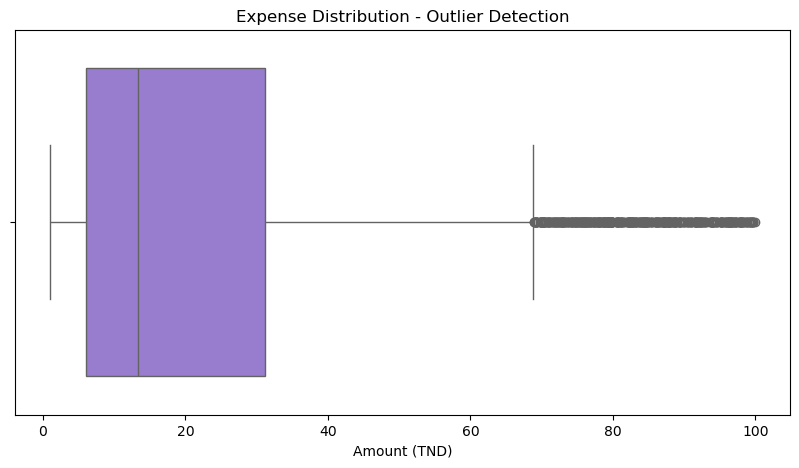

In [41]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["amount_tnd"],
    color="mediumpurple"
)

plt.title("Expense Distribution - Outlier Detection")
plt.xlabel("Amount (TND)")

plt.show()

In [43]:
Q1 = df["amount_tnd"].quantile(0.25)
Q3 = df["amount_tnd"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["amount_tnd"] < lower_bound) |
    (df["amount_tnd"] > upper_bound)
]

print("Number of outliers:", len(outliers))

Number of outliers: 465


In [53]:
def detect_outliers(group):

    Q1 = group["amount_tnd"].quantile(0.25)
    Q3 = group["amount_tnd"].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return group[
        (group["amount_tnd"] < lower) |
        (group["amount_tnd"] > upper)
    ]


outliers_by_category = (
    df.groupby("category", group_keys=False)
)
outiliers_by_category=outliers_by_category.apply(detect_outliers)

print("Outliers by category:", len(outliers_by_category))

Outliers by category: 6


C:\Users\R I B\AppData\Local\Temp\ipykernel_18480\1437594312.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  outiliers_by_category=outliers_by_category.apply(detect_outliers)


In [55]:
df["category"].unique()

array(['Transport', 'Entertainment', 'Education', 'Shopping', 'Coffee',
       'Food'], dtype=object)

In [57]:
df["city"].unique()

array(['Tunis', 'Nabeul', 'Sfax', 'Sousse', 'Monastir'], dtype=object)

In [59]:
df["payment_method"].value_counts()

payment_method
Cash    3801
Card    3764
Name: count, dtype: int64

In [61]:
budget_check = (
    df.groupby("student_id")["monthly_budget"]
    .nunique()
)

print(budget_check[budget_check > 1])

Series([], Name: monthly_budget, dtype: int64)


In [63]:
df["day_of_week"] = df["date"].dt.day_name()

In [65]:
df["is_weekend"] = df["date"].dt.dayofweek >= 5

In [67]:
def classify_expense(amount):

    if amount < 5:
        return "Small"

    elif amount < 20:
        return "Medium"

    else:
        return "Large"


df["expense_size"] = df["amount_tnd"].apply(
    classify_expense
)

In [69]:
df_clean = df.copy()

# Supprimer les transactions sans date ou montant valide
df_clean = df_clean.dropna(
    subset=["date", "amount_tnd", "monthly_budget"]
)

# Conserver uniquement les montants positifs
df_clean = df_clean[
    (df_clean["amount_tnd"] > 0) &
    (df_clean["monthly_budget"] > 0)
].copy()

print("Original dataset:", len(df))
print("Cleaned dataset:", len(df_clean))

Original dataset: 7565
Cleaned dataset: 7565


In [71]:
df_clean.to_csv(
    "../data/processed/cleaned_student_expenses.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
